In [253]:
ctu_path = (
    root / "data" / "raw" / "ctu-13"
    / "capture20110815-2.binetflow"
)

ctu_sample = pd.read_csv(ctu_path, nrows=5)

print("Số cột:", len(ctu_sample.columns))
print("\nDanh sách cột:")
print(ctu_sample.columns.tolist())

print("\n5 dòng đầu:")
display(ctu_sample.head())

print("\nKiểu dữ liệu:")
print(ctu_sample.dtypes)

Số cột: 15

Danh sách cột:
['StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir', 'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes', 'Label']

5 dòng đầu:


,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label
0,2011/08/15 16:43:20.931208,1783.916870,tcp,147.32.84.59,64131,<?>,164.8.32.159,54992,PA_PA,0,0,293,32160,20485,flow=Background-Established-cmpgw-CVUT
1,2011/08/15 16:43:20.933428,0.444453,tcp,147.32.87.252,49218,<?>,147.32.80.13,3128,FPA_FPA,0,0,879,747909,19566,flow=To-Background-CVUT-Proxy
2,2011/08/15 16:43:20.933441,1804.837158,tcp,41.143.58.184,1328,<?>,147.32.86.179,58675,PA_PA,0,0,9547,942226,580940,flow=Background
3,2011/08/15 16:43:20.933541,0.187604,tcp,147.32.86.155,51273,<?>,204.154.94.81,80,FA_FA,0,0,3,198,132,flow=Background
4,2011/08/15 16:43:20.933942,1804.610718,tcp,147.32.86.179,58675,<?>,151.42.234.124,50001,PA_PA,0,0,29890,3689108,917036,flow=Background



Kiểu dữ liệu:
StartTime        str
Dur          float64
Proto            str
SrcAddr          str
Sport          int64
Dir              str
DstAddr          str
Dport          int64
State            str
sTos           int64
dTos           int64
TotPkts        int64
TotBytes       int64
SrcBytes       int64
Label            str
dtype: object


Tốt! Chúng ta đã khảo sát cấu trúc ban đầu của cả ba bộ dữ liệu: UNSW-NB15, CIC-IDS2017 và CTU-13.

Kết quả CTU-13 lần này đặc biệt quan trọng, vì nó có những thông tin mà UNSW-NB15 Training/Testing đang sử dụng không cung cấp đầy đủ: IP nguồn, IP đích, cổng và thời gian bắt đầu flow.

Điều này giúp chúng ta phân biệt rõ hơn dữ liệu nào có thể phục vụ ML theo từng flow và dữ liệu nào có thể phục vụ DL theo chuỗi hành vi.

# 1. Phân tích kết quả CTU-13

Bạn đã xác minh file `capture20110815-2.binetflow` có 15 cột.

| Field CTU-13         | Ý nghĩa                     | Khả năng sử dụng                                  |
| -------------------- | --------------------------- | ------------------------------------------------- |
| `StartTime`          | Thời gian bắt đầu flow      | Sắp xếp, tổng hợp theo thời gian                  |
| `Dur`                | Thời lượng flow, giây       | Feature `duration_seconds` ứng viên               |
| `Proto`              | Giao thức                   | Feature `protocol`                                |
| `SrcAddr`, `DstAddr` | IP nguồn, IP đích           | Nhóm hoạt động theo host                          |
| `Sport`, `Dport`     | Cổng nguồn, đích            | Phân tích hành vi kết nối                         |
| `Dir`                | Hướng giao tiếp được mã hóa | Cần diễn giải trước khi ánh xạ                    |
| `TotPkts`            | Tổng số packet              | `total_packets` ứng viên                          |
| `TotBytes`           | Tổng số byte                | `total_bytes` ứng viên                            |
| `SrcBytes`           | Byte gửi từ nguồn           | Feature theo chiều nguồn, cần đối chiếu           |
| `State`              | Trạng thái flow             | Feature bổ sung tiềm năng                         |
| `Label`              | Nhãn lưu lượng              | Đánh giá mô hình, không đưa trực tiếp vào đầu vào |

Các định nghĩa chính này phù hợp với tài liệu CTU-13 và mô tả định dạng Argus của Stratosphere Laboratory.&#x20;




## 2. Điểm quan trọng nhất: CTU-13 có thể phục vụ nghiên cứu DL theo chuỗi

Giả sử chúng ta muốn phát hiện một IP liên tục thử kết nối đến nhiều cổng.

Thay vì chỉ xem một flow, hệ thống có thể nghiên cứu một chuỗi:

Ví dụ minh họa: Các flow của cùng một IP nguồn

10:00:01 -> Cổng 21

10:00:02 -> Cổng 22

10:00:03 -> Cổng 23

Đây chỉ là ví dụ về chuỗi cần nghiên cứu, không phải bản ghi đã tìm thấy trong CTU-13.

Với các trường `SrcAddr`, `Dport`, `StartTime`, chúng ta có thể nghiên cứu những đặc trưng như số flow theo cửa sổ thời gian, số cổng đích khác nhau và tần suất kết nối.

Tuy nhiên, cần lưu ý hai giới hạn:

- CTU-13 chủ yếu phục vụ nghiên cứu botnet, không được mặc nhiên coi nhãn Botnet là nhãn Port Scanning.&#x20;

- Một số flow kéo dài hơn 1.800 giây trong mẫu của bạn. Vì vậy, cần phân biệt thời gian bắt đầu flow và thời điểm flow thực sự hoàn tất khi xây pipeline xử lý theo thời gian.

Điều này có nghĩa CTU-13 là nguồn dữ liệu ứng viên cho DL theo chuỗi, chưa phải dataset DL đã được chốt.

# 3. Bảng tổng hợp ba dataset và Suricata

Bây giờ chúng ta đã có bức tranh tổng quan:

| Đặc trưng         | UNSW-NB15                        | CIC-IDS2017                    | CTU-13                                                | Suricata        |
| ----------------- | -------------------------------- | ------------------------------ | ----------------------------------------------------- | --------------- |
| Duration          | `dur`                            | `Flow Duration`                | `Dur`                                                 | `end - start`   |
| Protocol          | `proto`                          | Chưa xác nhận từ file này      | `Proto`                                               | `proto`         |
| Tổng packet       | Tính từ `spkts + dpkts`          | Tính từ Fwd + Bwd              | `TotPkts`                                             | Tổng hai chiều  |
| Tổng byte         | Tính từ `sbytes + dbytes`        | Tính từ Fwd + Bwd              | `TotBytes`                                            | Tổng hai chiều  |
| Packet từng chiều | Có                               | Có                             | Không có trực tiếp trong 15 cột                       | Có              |
| Byte từng chiều   | Có                               | Có                             | Có `SrcBytes`; chiều còn lại cần xác minh phép suy ra | Có              |
| IP nguồn/đích     | Không có trong hai CSV đang dùng | Cần kiểm tra                   | Có                                                    | Có trên TCP mẫu |
| Thời điểm bắt đầu | Không có trong hai CSV đang dùng | Cần kiểm tra                   | Có                                                    | Có              |
| Cổng nguồn/đích   | Không có trong hai CSV đang dùng | Có thể có, cần kiểm tra header | Có                                                    | Có trên TCP mẫu |

Đây là bảng về mức độ sẵn có của dữ liệu, chưa phải xác nhận các đại lượng hoàn toàn tương đương.

Điểm đáng chú ý là chúng ta không nên ép mọi dataset có cùng toàn bộ feature. Hợp lý hơn là xây:

- Một Flow Feature Schema cho ML.
- Một Sequence Feature Schema cho DL, sử dụng dữ liệu có IP và timestamp.

# 4. Tiếp tục Phase 04.3.4 — Kiểm tra nhãn và tính nhất quán CTU-13

Trước khi quyết định sử dụng CTU-13, có hai vấn đề cần xác minh.

Thứ nhất: Nhãn `Background` có nghĩa là gì?

Trong CTU-13, `Background` không đồng nghĩa chắc chắn với `Normal`. Theo Stratosphere Laboratory, Background là lưu lượng còn lại mà họ không thể khẳng định hoàn toàn là bình thường hay độc hại.&#x20;



Vì vậy, ta không được tự động gộp `Background` vào `Normal` khi huấn luyện mô hình học hành vi bình thường.

Thứ hai: `SrcBytes` có hợp lệ để suy ra byte chiều còn lại không?

Về mặt số học, nếu `SrcBytes` là một phần của `TotBytes`, thì có thể tính:

\\[ \text{DstBytes}=\text{TotBytes}-\text{SrcBytes} \\]

Nhưng trước khi làm điều đó, cần xác minh dữ liệu không có giá trị bất thường và ngữ nghĩa hai bộ đếm nhất quán.

## 5. Tiến độ Phase 04

| Bước                                   | Trạng thái                               |
| -------------------------------------- | ---------------------------------------- |
| 04.1 — Data Quality Profiling          | Đã thực hiện các kiểm tra chính của UNSW |
| 04.2 — Suricata Feature Extractor      | Đã PASS phiên bản cơ bản                 |
| 04.3.1 — UNSW Schema Inventory         | Hoàn thành                               |
| 04.3.2 — CIC Schema Inventory          | Hoàn thành khảo sát ban đầu              |
| 04.3.3 — CTU Schema Inventory          | Hoàn thành khảo sát ban đầu              |
| 04.3.4 — CTU Label & Consistency       | Đang thực hiện                           |
| 04.3.5 — Chốt Schema chung             | Chưa                                     |
| 04.4 — Correlation & Feature Selection | Chưa                                     |
| 04.5 — Preprocessing                   | Chưa                                     |
| 04.6 — Kiểm thử pipeline               | Chưa                                     |

Chúng ta đã có đủ thông tin ban đầu để không cần tiếp tục khám phá thêm nhiều feature một cách thiếu định hướng. Việc tiếp theo nên tập trung vào kiểm chứng dữ liệu, xác định phần giao nhau có ý nghĩa giữa các nguồn và chốt schema cho từng nhánh.

Bạn chạy ô code ở mục 4 và gửi kết quả. Sau đó mình sẽ hướng dẫn kiểm tra toàn bộ CTU-13 theo chunk, rồi chúng ta bắt đầu chốt Canonical Feature Schema v1, một quyết định kỹ thuật quan trọng cần ghi rõ trong README Phase 04.

In [254]:
print("Nhãn trong mẫu:")
display(ctu_sample["Label"].value_counts())

print("\nGiá trị hướng giao tiếp:")
display(ctu_sample["Dir"].value_counts())

print("\nKiểm tra byte:")
print(
    "SrcBytes > TotBytes:",
    (ctu_sample["SrcBytes"] > ctu_sample["TotBytes"]).sum()
)

print(
    "SrcBytes âm:",
    (ctu_sample["SrcBytes"] < 0).sum()
)

Nhãn trong mẫu:


Label
flow=Background                           3
flow=Background-Established-cmpgw-CVUT    1
flow=To-Background-CVUT-Proxy             1
Name: count, dtype: int64


Giá trị hướng giao tiếp:


Dir
<?>    5
Name: count, dtype: int64


Kiểm tra byte:
SrcBytes > TotBytes: 0
SrcBytes âm: 0


### Bản nhóm nhãn trong CTU-13
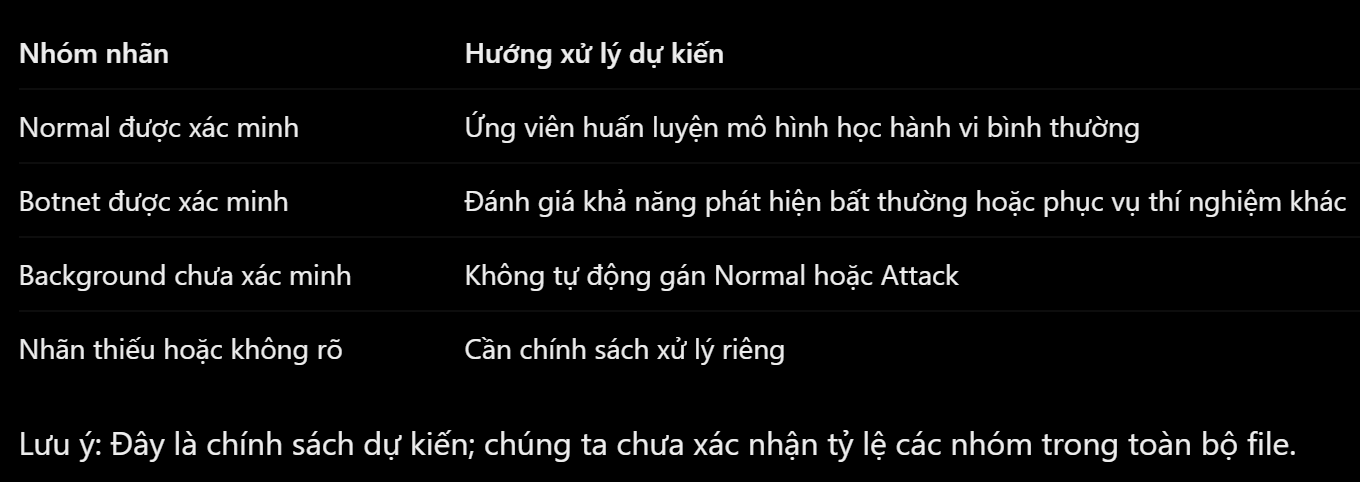

In [255]:
from collections import Counter

label_counts = Counter()
dir_counts = Counter()
total_rows = 0

for chunk in pd.read_csv(
    ctu_path,
    usecols=["Label", "Dir"],
    chunksize=50_000
):
    total_rows += len(chunk)

    labels = chunk["Label"].fillna("<MISSING>")
    directions = chunk["Dir"].fillna("<MISSING>").str.strip()

    label_counts.update(labels.value_counts().to_dict())
    dir_counts.update(directions.value_counts().to_dict())

print("Tổng số bản ghi:", total_rows)

print("\nTop 15 nhãn:")
for label, count in label_counts.most_common(15):
    print(count, "|", label)

print("\nPhân phối hướng giao tiếp:")
for direction, count in dir_counts.most_common():
    print(repr(direction), ":", count)

Tổng số bản ghi: 129832

Top 15 nhãn:
50817 | flow=To-Background-UDP-CVUT-DNS-Server
37203 | flow=Background-UDP-Established
15156 | flow=Background-TCP-Established
9331 | flow=Background-Established-cmpgw-CVUT
3426 | flow=Background
2893 | flow=Background-UDP-Attempt
1847 | flow=Background-TCP-Attempt
1810 | flow=From-Normal-V46-Stribrek
1722 | flow=From-Normal-V46-Grill
1340 | flow=To-Background-CVUT-Proxy
1107 | flow=From-Normal-V46-Jist
470 | flow=Background-Attempt-cmpgw-CVUT
422 | flow=From-Botnet-V46-TCP-Attempt
317 | flow=Background-UDP-NTP-Established-1
254 | flow=To-Background-CVUT-WebServer

Phân phối hướng giao tiếp:
'<->' : 92606
'->' : 34748
'<?>' : 1512
'<-' : 570
'?>' : 325
'who' : 71


### Phân tích kết quả CTU-13
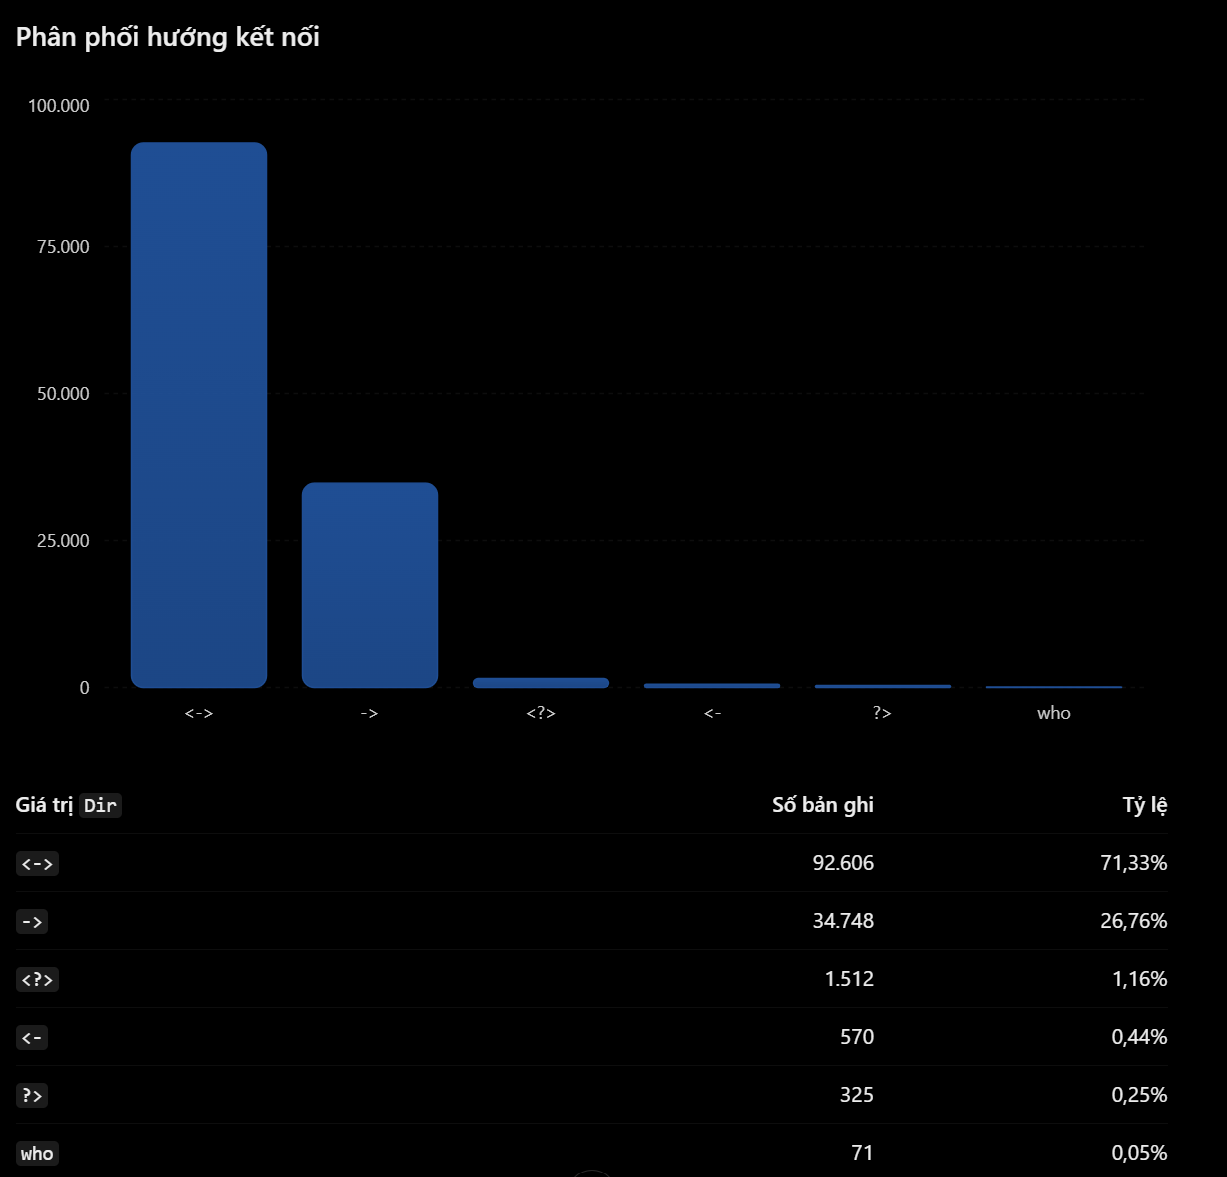

Chúng ta tạm thời phân định vai trò các nguồn dữ liệu:

| Nguồn | Vai trò nghiên cứu dự kiến |
| :--- | :--- |
| **UNSW-NB15** | ML phát hiện bất thường theo từng flow |
| **CIC-IDS2017** | Kiểm tra feature mapping và nghiên cứu tấn công DDoS/PortScan |
| **CTU-13** | Nghiên cứu chuỗi hành vi theo thời gian, phục vụ nhánh DL |
| **Suricata EVE JSON** | Dữ liệu thực tế để kiểm thử trích xuất feature và triển khai |

*Lưu ý: Đây vẫn là định hướng, chưa phải kết luận rằng cả ba dataset đều có thể dùng chung một mô hình.*

Đối với **CTU-13**, ta sẽ không tự động biến `Background` thành dữ liệu sạch. Khi dùng `Isolation Forest` hoặc `GRU Autoencoder` học hành vi bình thường, chất lượng tập `Normal` có ảnh hưởng trực tiếp đến kết quả.


In [256]:
from collections import Counter

label_groups = Counter()

for label, count in label_counts.items():
    if "Botnet" in label:
        group = "Botnet"
    elif "Normal" in label:
        group = "Normal"
    elif "Background" in label:
        group = "Background"
    else:
        group = "Other"

    label_groups[group] += count

for group, count in label_groups.items():
    percentage = count / total_rows * 100
    print(f"{group}: {count} ({percentage:.2f}%)")

assert sum(label_groups.values()) == total_rows
print("Label grouping: PASS")

Background: 124252 (95.70%)
Normal: 4679 (3.60%)
Botnet: 901 (0.69%)
Label grouping: PASS


Qua khảo sát 129.832 bản ghi của CTU-13, dữ liệu có nhiều dạng nhãn chi tiết và các ký hiệu hướng kết nối khác nhau. Do nhóm Background không mặc nhiên đại diện cho lưu lượng bình thường, nghiên cứu cần phân loại và xác minh nhãn trước khi sử dụng để huấn luyện mô hình phát hiện bất thường. CTU-13 có các trường thời gian, địa chỉ nguồn/đích và cổng kết nối, tạo điều kiện nghiên cứu các đặc trưng hành vi theo chuỗi thời gian.

In [257]:

import pandas as pd

# Thay df bằng tên DataFrame CTU-13 hiện tại của bạn
data = df

print("=== DATASET OVERVIEW ===")
print("Shape:", data.shape)
print("Columns:", data.columns.tolist())

print("\n=== MISSING VALUES ===")
missing = pd.DataFrame({
    "Missing": data.isna().sum(),
    "Missing (%)": (data.isna().mean() * 100).round(2)
})
display(missing[missing["Missing"] > 0])

print("\n=== DUPLICATE ROWS ===")
print("Duplicates:", data.duplicated().sum())

print("\n=== ORIGINAL LABELS ===")
if "Label" in data.columns:
    display(data["Label"].value_counts(dropna=False))

print("\n=== INVALID NUMERICAL VALUES ===")
for col in ["Dur", "TotPkts", "TotBytes", "SrcBytes"]:
    if col in data.columns:
        values = pd.to_numeric(data[col], errors="coerce")
        print(
            f"{col}:",
            "Invalid =", values.isna().sum(),
            "| Negative =", (values < 0).sum()
        )

print("\n=== TIMESTAMP VALIDATION ===")
if "StartTime" in data.columns:
    times = pd.to_datetime(data["StartTime"], errors="coerce")
    print("Invalid timestamps:", times.isna().sum())
    print("Start:", times.min())
    print("End:", times.max())


=== DATASET OVERVIEW ===
Shape: (5, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

=== MISSING VALUES ===


,Missing,Missing (%)



=== DUPLICATE ROWS ===
Duplicates: 0

=== ORIGINAL LABELS ===

=== INVALID NUMERICAL VALUES ===

=== TIMESTAMP VALIDATION ===


#### Kết quả audit này chưa hợp lệ để đánh giá CTU-13. Có thể biến df đã bị ghi đè bởi dữ liệu UNSW-NB15 hoặc một DataFrame mẫu.

In [258]:
import pandas as pd

print("=== AVAILABLE DATAFRAMES ===")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = {str(c).lower() for c in obj.columns}

        is_ctu = {"starttime", "srcaddr", "dstaddr", "label"}.issubset(cols)
        is_unsw = {"spkts", "dpkts", "attack_cat"}.issubset(cols)

        dataset = (
            "CTU-13" if is_ctu else
            "UNSW-NB15" if is_unsw else
            "Unknown"
        )

        print(f"{name}: {obj.shape} | {dataset}")


=== AVAILABLE DATAFRAMES ===
df: (5, 45) | UNSW-NB15
train_df: (175341, 45) | UNSW-NB15
label_table: (10, 2) | Unknown
feature_df: (175341, 42) | Unknown
numeric_df: (175341, 41) | Unknown
conflict_df: (940, 45) | UNSW-NB15
candidate_features: (5, 42) | Unknown
test_df: (82332, 45) | UNSW-NB15
train_features: (175341, 42) | Unknown
test_features: (82332, 42) | Unknown
overlap_by_label: (2, 2) | Unknown
train_label_summary: (101040, 2) | Unknown
overlap_df: (8541, 3) | Unknown
candidate_test: (8541, 42) | Unknown
candidate_train: (1302, 42) | Unknown
exact_check: (8541, 43) | Unknown
mapping: (6, 3) | Unknown
cic_sample: (5, 79) | Unknown
ctu_sample: (5, 15) | CTU-13
chunk: (29832, 2) | Unknown
data: (5, 45) | UNSW-NB15
missing: (45, 2) | Unknown


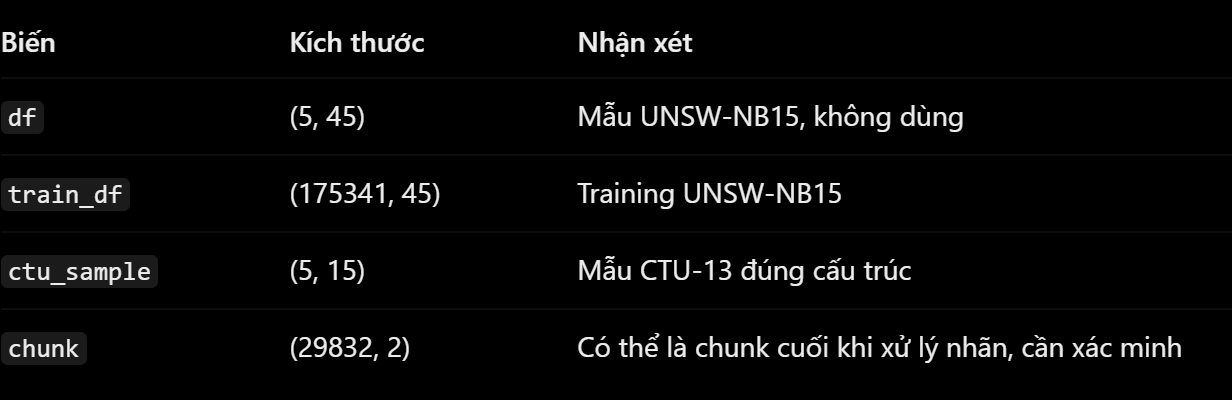

In [260]:
import pandas as pd

# Dùng đúng đường dẫn file đã sử dụng
# trong bước CTU-13 Label Grouping trước đó.
ctu_path = r"D:\suricata-ai-project\data\raw\ctu-13\capture20110815-2.binetflow"

ctu_df = pd.read_csv(ctu_path, low_memory=False)
ctu_df.columns = ctu_df.columns.str.strip()

print("=== CTU-13 DATASET ===")
print("Shape:", ctu_df.shape)
print("Columns:", ctu_df.columns.tolist())

if len(ctu_df) != 129832:
    print("WARNING: Row count differs from previous grouping!")

print("\n=== MISSING VALUES ===")
missing = ctu_df.isna().sum()
display(missing[missing > 0].to_frame("Missing"))

print("\n=== DUPLICATE ROWS ===")
print("Duplicates:", ctu_df.duplicated().sum())

print("\n=== ORIGINAL LABELS ===")
display(ctu_df["Label"].value_counts(dropna=False))

print("\n=== INVALID NUMERIC VALUES ===")
for col in ["Dur", "TotPkts", "TotBytes", "SrcBytes"]:
    if col in ctu_df.columns:
        values = pd.to_numeric(ctu_df[col], errors="coerce")
        print(
            col,
            "| Invalid:", values.isna().sum(),
            "| Negative:", (values < 0).sum()
        )

print("\n=== TIMESTAMP ===")
times = pd.to_datetime(
    ctu_df["StartTime"], errors="coerce"
)
print("Invalid timestamps:", times.isna().sum())
print("Earliest:", times.min())
print("Latest:", times.max())


=== CTU-13 DATASET ===
Shape: (129832, 15)
Columns: ['StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir', 'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes', 'Label']

=== MISSING VALUES ===


,Missing
Sport,797
Dport,377
sTos,858
dTos,6896



=== DUPLICATE ROWS ===
Duplicates: 0

=== ORIGINAL LABELS ===


Label
flow=To-Background-UDP-CVUT-DNS-Server                      50817
flow=Background-UDP-Established                             37203
flow=Background-TCP-Established                             15156
flow=Background-Established-cmpgw-CVUT                       9331
flow=Background                                              3426
                                                            ...  
flow=From-Botnet-V46-TCP-HTTP-Google-Net-Established-6          1
flow=From-Botnet-V46-TCP-CC7-Custom-Encryption                  1
flow=From-Botnet-V46-TCP-Established-HTTP-Ad-4                  1
flow=From-Botnet-V46-TCP-Established-Custom-Encryption-8        1
flow=From-Botnet-V46-TCP-Established                            1
Name: count, Length: 77, dtype: int64


=== INVALID NUMERIC VALUES ===
Dur | Invalid: 0 | Negative: 0
TotPkts | Invalid: 0 | Negative: 0
TotBytes | Invalid: 0 | Negative: 0
SrcBytes | Invalid: 0 | Negative: 0

=== TIMESTAMP ===
Invalid timestamps: 0
Earliest: 2011-08-15 16:43:20.931208
Latest: 2011-08-15 17:13:26.758894


Xác minh 77 nhãn gốc có được nhóm nhất quán thành Background, Normal và Botnet không.



Phát hiện nhãn không xác định hoặc đồng thời khớp nhiều nhóm.



Kiểm tra các giá trị thiếu có tập trung ở TCP, UDP, ICMP hay không.



Chưa thay đổi dữ liệu gốc.

In [261]:

import pandas as pd

# 1. Validate original labels
labels = ctu_df["Label"].astype("string").str.strip()

flags = pd.DataFrame({
    "Background": labels.str.contains(
        "Background", case=False, regex=False, na=False
    ),
    "Normal": labels.str.contains(
        "Normal", case=False, regex=False, na=False
    ),
    "Botnet": labels.str.contains(
        "Botnet", case=False, regex=False, na=False
    )
}, index=ctu_df.index)

match_count = flags.sum(axis=1)

print("=== LABEL VALIDATION ===")
print("Unmatched:", (match_count == 0).sum())
print("Ambiguous:", (match_count > 1).sum())

# 2. Assign only unambiguous groups
ctu_group = pd.Series(
    "Unclassified",
    index=ctu_df.index,
    name="LabelGroup"
)

for group in flags.columns:
    valid = flags[group] & (match_count == 1)
    ctu_group.loc[valid] = group

ctu_group.loc[match_count > 1] = "Ambiguous"

print("\n=== LABEL DISTRIBUTION ===")
display(ctu_group.value_counts().to_frame("Count"))

# 3. Inspect problematic labels, if any
problematic = ctu_group.isin(
    ["Unclassified", "Ambiguous"]
)

if problematic.any():
    print("\n=== PROBLEMATIC ORIGINAL LABELS ===")
    display(
        ctu_df.loc[problematic, "Label"]
        .value_counts()
        .head(20)
    )

# 4. Missing values by protocol
cols = ["Sport", "Dport", "sTos", "dTos"]

print("\n=== MISSING (%) BY PROTOCOL ===")
missing_by_proto = (
    ctu_df.groupby("Proto")[cols]
    .agg(lambda x: x.isna().mean() * 100)
    .round(2)
)
display(missing_by_proto)

# 5. Missing values by label group
print("\n=== MISSING (%) BY LABEL GROUP ===")
missing_by_group = (
    ctu_df.assign(LabelGroup=ctu_group)
    .groupby("LabelGroup")[cols]
    .agg(lambda x: x.isna().mean() * 100)
    .round(2)
)
display(missing_by_group)

print("\n=== VALIDATION ===")
if (match_count == 1).all():
    print("PASS: All records mapped unambiguously.")
else:
    print("REVIEW: Some labels require manual validation.")


=== LABEL VALIDATION ===
Unmatched: 0
Ambiguous: 0

=== LABEL DISTRIBUTION ===


,Count
LabelGroup,
Background,124252
Normal,4679
Botnet,901



=== MISSING (%) BY PROTOCOL ===


,Sport,Dport,sTos,dTos
Proto,,,,
arp,100.00,100.00,100.00,100.00
icmp,27.64,4.22,27.64,69.50
igmp,100.00,100.00,0.00,100.00
ipv6-icmp,0.00,100.00,0.00,100.00
ipx/spx,100.00,100.00,100.00,100.00
pim,100.00,100.00,0.00,100.00
rsvp,100.00,100.00,0.00,100.00
rtcp,0.00,0.00,0.00,0.00
rtp,0.00,0.00,0.00,0.00



=== MISSING (%) BY LABEL GROUP ===


,Sport,Dport,sTos,dTos
LabelGroup,,,,
Background,0.64,0.30,0.69,5.42
Botnet,0.00,0.00,0.00,16.87
Normal,0.06,0.06,0.06,0.19



=== VALIDATION ===
PASS: All records mapped unambiguously.


- Toàn bộ 129.832 bản ghi được phân vào đúng một trong ba nhóm: Background (124.252), Normal (4.679) và Botnet (901). Không có nhãn chưa phân loại hoặc khớp nhiều nhóm.
- Tuy nhiên, PASS mới chứng minh quy tắc đối sánh chuỗi hoạt động nhất quán, chưa chứng minh tất cả nhãn gốc đều chính xác về mặt an ninh mạng.
- Các kết quả đáng chú ý:
    - ARP, IGMP và một số giao thức khác: Sport, Dport thiếu 100%. Điều này có thể hợp lý vì chúng không sử dụng cổng TCP/UDP theo cách thông thường.
    - TCP: dTos thiếu 6,71%.
    - UDP: dTos thiếu 3,23%.
    - Botnet: dTos thiếu 16,87%, cao hơn mức 5,42% của Background và 0,19% của Normal.
- Điểm cuối rất đáng nghiên cứu. Nếu thay tất cả giá trị thiếu của dTos bằng 0, mô hình có thể học sự khác biệt về cách ghi nhận dữ liệu thay vì hành vi tấn công thực sự.

=> Vì vậy, chưa điền giá trị thiếu, chưa xóa bản ghi và chưa cân bằng dữ liệu.

In [262]:
import pandas as pd

# Work on a copy, preserve original dataset
audit_df = ctu_df.copy()
audit_df["LabelGroup"] = ctu_group

# 1. Protocol distribution by label
print("=== PROTOCOL DISTRIBUTION (COUNT) ===")

proto_count = pd.crosstab(
    audit_df["LabelGroup"],
    audit_df["Proto"]
)
display(proto_count)

# 2. Within-group protocol percentages
print("\n=== PROTOCOL DISTRIBUTION (%) ===")

proto_pct = (
    proto_count.div(proto_count.sum(axis=1), axis=0)
    * 100
).round(2)

display(proto_pct)

# 3. Missing dTos by group and protocol
print("\n=== MISSING dTos BY GROUP AND PROTOCOL ===")

dtos_missing = (
    audit_df.assign(dTosMissing=audit_df["dTos"].isna())
    .groupby(["LabelGroup", "Proto"])
    .agg(
        Records=("dTosMissing", "size"),
        Missing=("dTosMissing", "sum"),
        MissingPct=("dTosMissing", "mean")
    )
)

dtos_missing["MissingPct"] *= 100
display(dtos_missing.round(2))

# 4. Temporal distribution by 5-minute intervals
print("\n=== TEMPORAL DISTRIBUTION (5 MIN) ===")

timestamps = pd.to_datetime(
    audit_df["StartTime"], errors="coerce"
)

time_bins = timestamps.dt.floor("5min")

temporal_count = pd.crosstab(
    time_bins,
    audit_df["LabelGroup"]
)

display(temporal_count)

print("\n=== VALIDATION ===")
print("Total records:", proto_count.to_numpy().sum())
print("Time bins:", len(temporal_count))
print("Missing timestamps:", timestamps.isna().sum())


=== PROTOCOL DISTRIBUTION (COUNT) ===


Proto,arp,icmp,igmp,ipv6-icmp,ipx/spx,pim,rsvp,rtcp,rtp,tcp,udp
LabelGroup,,,,,,,,,,,
Background,68,2062,150,11,1,1,1,68,28,29354,92508
Botnet,0,0,0,0,0,0,0,0,0,849,52
Normal,3,0,0,0,0,0,0,0,0,1696,2980



=== PROTOCOL DISTRIBUTION (%) ===


Proto,arp,icmp,igmp,ipv6-icmp,ipx/spx,pim,rsvp,rtcp,rtp,tcp,udp
LabelGroup,,,,,,,,,,,
Background,0.05,1.66,0.12,0.01,0.0,0.0,0.0,0.05,0.02,23.62,74.45
Botnet,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.00,94.23,5.77
Normal,0.06,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.00,36.25,63.69



=== MISSING dTos BY GROUP AND PROTOCOL ===


Records  Missing  MissingPct
LabelGroup Proto                                  
Background arp             68       68      100.00
           icmp          2062     1433       69.50
           igmp           150      150      100.00
           ipv6-icmp       11       11      100.00
           ipx/spx          1        1      100.00
           pim              1        1      100.00
           rsvp             1        1      100.00
           rtcp            68        0        0.00
           rtp             28        0        0.00
           tcp          29354     1989        6.78
           udp          92508     3081        3.33
Botnet     tcp            849      149       17.55
           udp             52        3        5.77
Normal     arp              3        3      100.00
           tcp           1696        1        0.06
           udp           2980        5        0.17


=== TEMPORAL DISTRIBUTION (5 MIN) ===


LabelGroup,Background,Botnet,Normal
StartTime,,,
2011-08-15 16:40:00,10151,0,127
2011-08-15 16:45:00,22364,0,484
2011-08-15 16:50:00,19905,44,1208
2011-08-15 16:55:00,19030,146,1434
2011-08-15 17:00:00,20163,284,827
2011-08-15 17:05:00,20735,306,481
2011-08-15 17:10:00,11904,121,118



=== VALIDATION ===
Total records: 129832
Time bins: 7
Missing timestamps: 0


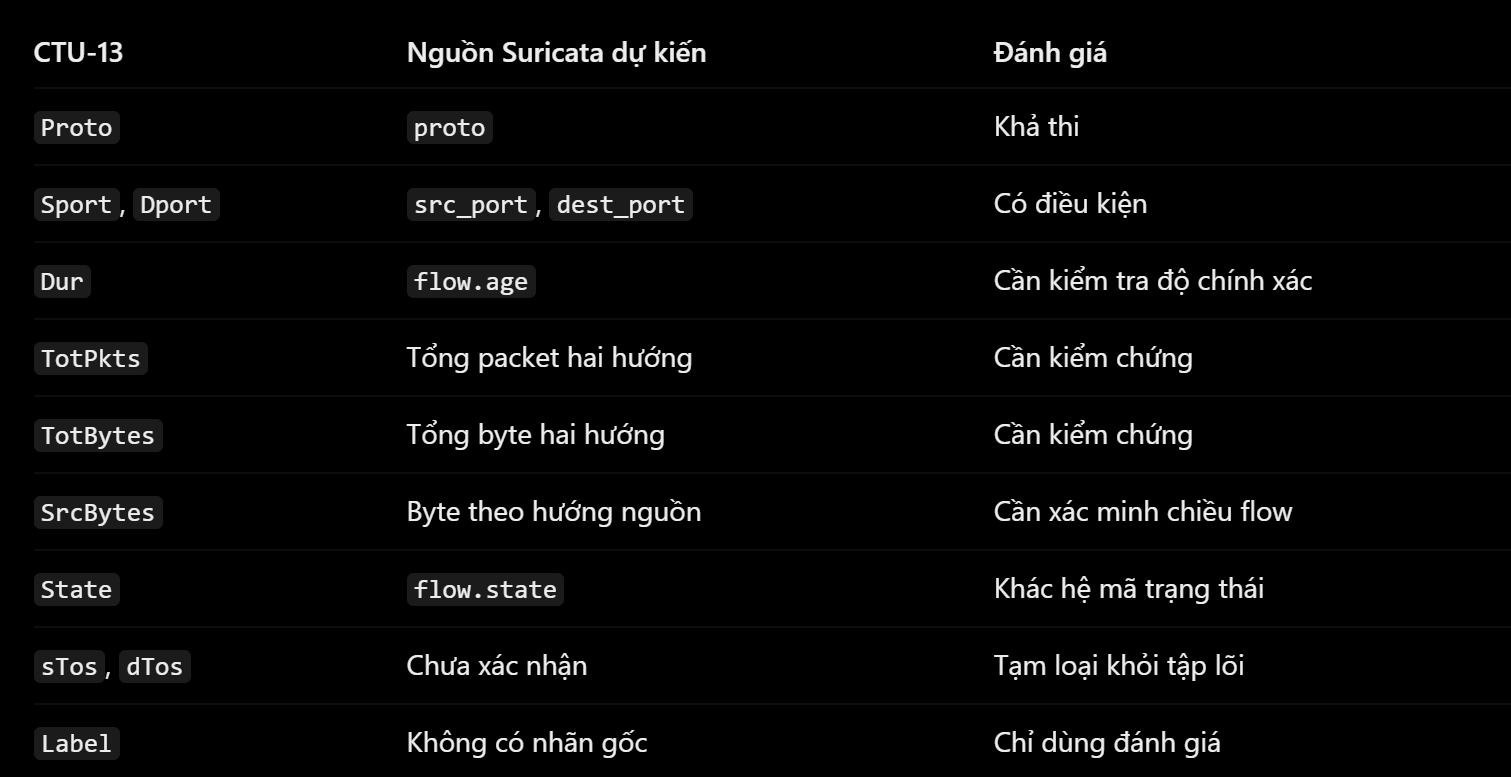

In [263]:

import json
import pandas as pd
from pathlib import Path

# Locate exported Suricata sample
paths = [
    Path("data/samples/suricata/suricata-flow-sample.json"),
    Path("../data/samples/suricata/suricata-flow-sample.json")
]

eve_path = next((p for p in paths if p.is_file()), None)

if eve_path is None:
    print("Suricata sample not found.")
    print("Check notebook working directory:")
    print(Path.cwd())
else:
    raw = eve_path.read_text(encoding="utf-8-sig")

    try:
        records = json.loads(raw)
    except json.JSONDecodeError:
        records = [
            json.loads(line)
            for line in raw.splitlines()
            if line.strip()
        ]

    if isinstance(records, dict):
        records = [records]

    flow_records = [
        r for r in records
        if isinstance(r, dict)
        and (
            r.get("event_type") == "flow"
            or (
                "event_type" not in r
                and isinstance(r.get("flow"), dict)
            )
        )
    ]

    eve_df = pd.json_normalize(flow_records)

    print("=== SURICATA FLOW SAMPLE ===")
    print("Flow records:", len(eve_df))
    print("Available fields:")
    print(eve_df.columns.tolist())

    # CTU to Suricata candidate mapping
    feature_map = {
        "Proto": ["proto"],
        "Sport": ["src_port"],
        "Dport": ["dest_port"],
        "Dur": ["flow.age"],
        "TotPkts": [
            "flow.pkts_toserver",
            "flow.pkts_toclient"
        ],
        "TotBytes": [
            "flow.bytes_toserver",
            "flow.bytes_toclient"
        ],
        "SrcBytes": [
            "flow.bytes_toserver",
            "flow.bytes_toclient"
        ],
        "State": ["flow.state"]
    }

    results = []

    for feature, required in feature_map.items():
        available = [
            col for col in required
            if col in eve_df.columns
        ]

        results.append({
            "CTU Feature": feature,
            "Required Fields": ", ".join(required),
            "Present": len(available),
            "Required": len(required),
            "Fields Available": (
                len(available) == len(required)
            )
        })

    print("\n=== FEATURE AVAILABILITY AUDIT ===")
    display(pd.DataFrame(results))


=== SURICATA FLOW SAMPLE ===
Flow records: 1
Available fields:
['timestamp', 'flow_id', 'in_iface', 'event_type', 'ip_v', 'proto', 'icmp_type', 'icmp_code', 'flow.pkts_toserver', 'flow.pkts_toclient', 'flow.bytes_toserver', 'flow.bytes_toclient', 'flow.start', 'flow.end', 'flow.age', 'flow.state', 'flow.reason', 'flow.alerted']

=== FEATURE AVAILABILITY AUDIT ===


,CTU Feature,Required Fields,Present,Required,Fields Available
0,Proto,proto,1,1,True
1,Sport,src_port,0,1,False
2,Dport,dest_port,0,1,False
3,Dur,flow.age,1,1,True
4,TotPkts,"flow.pkts_toserver, flow.pkts_toclient",2,2,True
5,TotBytes,"flow.bytes_toserver, flow.bytes_toclient",2,2,True
6,SrcBytes,"flow.bytes_toserver, flow.bytes_toclient",2,2,True
7,State,flow.state,1,1,True


In [264]:

import pandas as pd

# Preserve original CTU-13 data
ctu_audit = ctu_df.copy()
ctu_audit["LabelGroup"] = ctu_group

# Focus on TCP/UDP, matching the verified
# Suricata protocol coverage.
ctu_audit = ctu_audit[
    ctu_audit["Proto"].astype(str).str.lower()
    .isin(["tcp", "udp"])
].copy()

numeric_cols = [
    "Dur", "TotPkts", "TotBytes", "SrcBytes"
]

for col in numeric_cols:
    ctu_audit[col] = pd.to_numeric(
        ctu_audit[col], errors="coerce"
    )

print("=== TCP/UDP DATASET OVERVIEW ===")
print("Records:", len(ctu_audit))
display(ctu_audit["LabelGroup"].value_counts())

print("\n=== FEATURE CONSISTENCY CHECK ===")

checks = pd.DataFrame({
    "Zero duration": ctu_audit["Dur"] == 0,
    "Zero packets": ctu_audit["TotPkts"] == 0,
    "Zero bytes": ctu_audit["TotBytes"] == 0,
    "SrcBytes > TotBytes": (
        ctu_audit["SrcBytes"] > ctu_audit["TotBytes"]
    ),
    "Zero duration with packets": (
        (ctu_audit["Dur"] == 0) &
        (ctu_audit["TotPkts"] > 0)
    )
}, index=ctu_audit.index)

report = pd.DataFrame({
    "Count": checks.sum(),
    "Percent": (
        checks.mean() * 100
    ).round(3)
})

display(report)

print("\n=== FEATURE DISTRIBUTION BY LABEL ===")

for col in numeric_cols:
    print(f"\nFeature: {col}")

    stats = (
        ctu_audit.groupby("LabelGroup")[col]
        .agg(
            Count="count",
            Median="median",
            Mean="mean",
            Max="max"
        )
        .round(3)
    )

    display(stats)

print("\n=== VALIDATION ===")

if ctu_audit[numeric_cols].isna().any().any():
    print("REVIEW: Invalid or missing numeric features.")
else:
    print("PASS: Core numeric features are present.")

print("Original CTU-13 records:", len(ctu_df))
print("TCP/UDP records:", len(ctu_audit))
print("Excluded non-TCP/UDP:", len(ctu_df) - len(ctu_audit))


=== TCP/UDP DATASET OVERVIEW ===
Records: 127439


LabelGroup
Background    121862
Normal          4676
Botnet           901
Name: count, dtype: int64


=== FEATURE CONSISTENCY CHECK ===


,Count,Percent
Zero duration,1020,0.8
Zero packets,0,0.0
Zero bytes,0,0.0
SrcBytes > TotBytes,0,0.0
Zero duration with packets,1020,0.8



=== FEATURE DISTRIBUTION BY LABEL ===

Feature: Dur


,Count,Median,Mean,Max
LabelGroup,,,,
Background,121862,0.001,78.156,1805.828
Botnet,901,1.593,6.489,1139.729
Normal,4676,0.002,27.803,1805.375


... (3 outputs left out)

,Count,Median,Mean,Max
LabelGroup,,,,
Background,121862,265.0,28301.020,853704136
Botnet,901,366.0,22660.565,615599
Normal,4676,396.0,58348.089,137416417



Feature: SrcBytes


,Count,Median,Mean,Max
LabelGroup,,,,
Background,121862,81.0,3980.623,85080318
Botnet,901,186.0,10965.527,600198
Normal,4676,81.0,34906.984,136546777



=== VALIDATION ===
PASS: Core numeric features are present.
Original CTU-13 records: 129832
TCP/UDP records: 127439
Excluded non-TCP/UDP: 2393


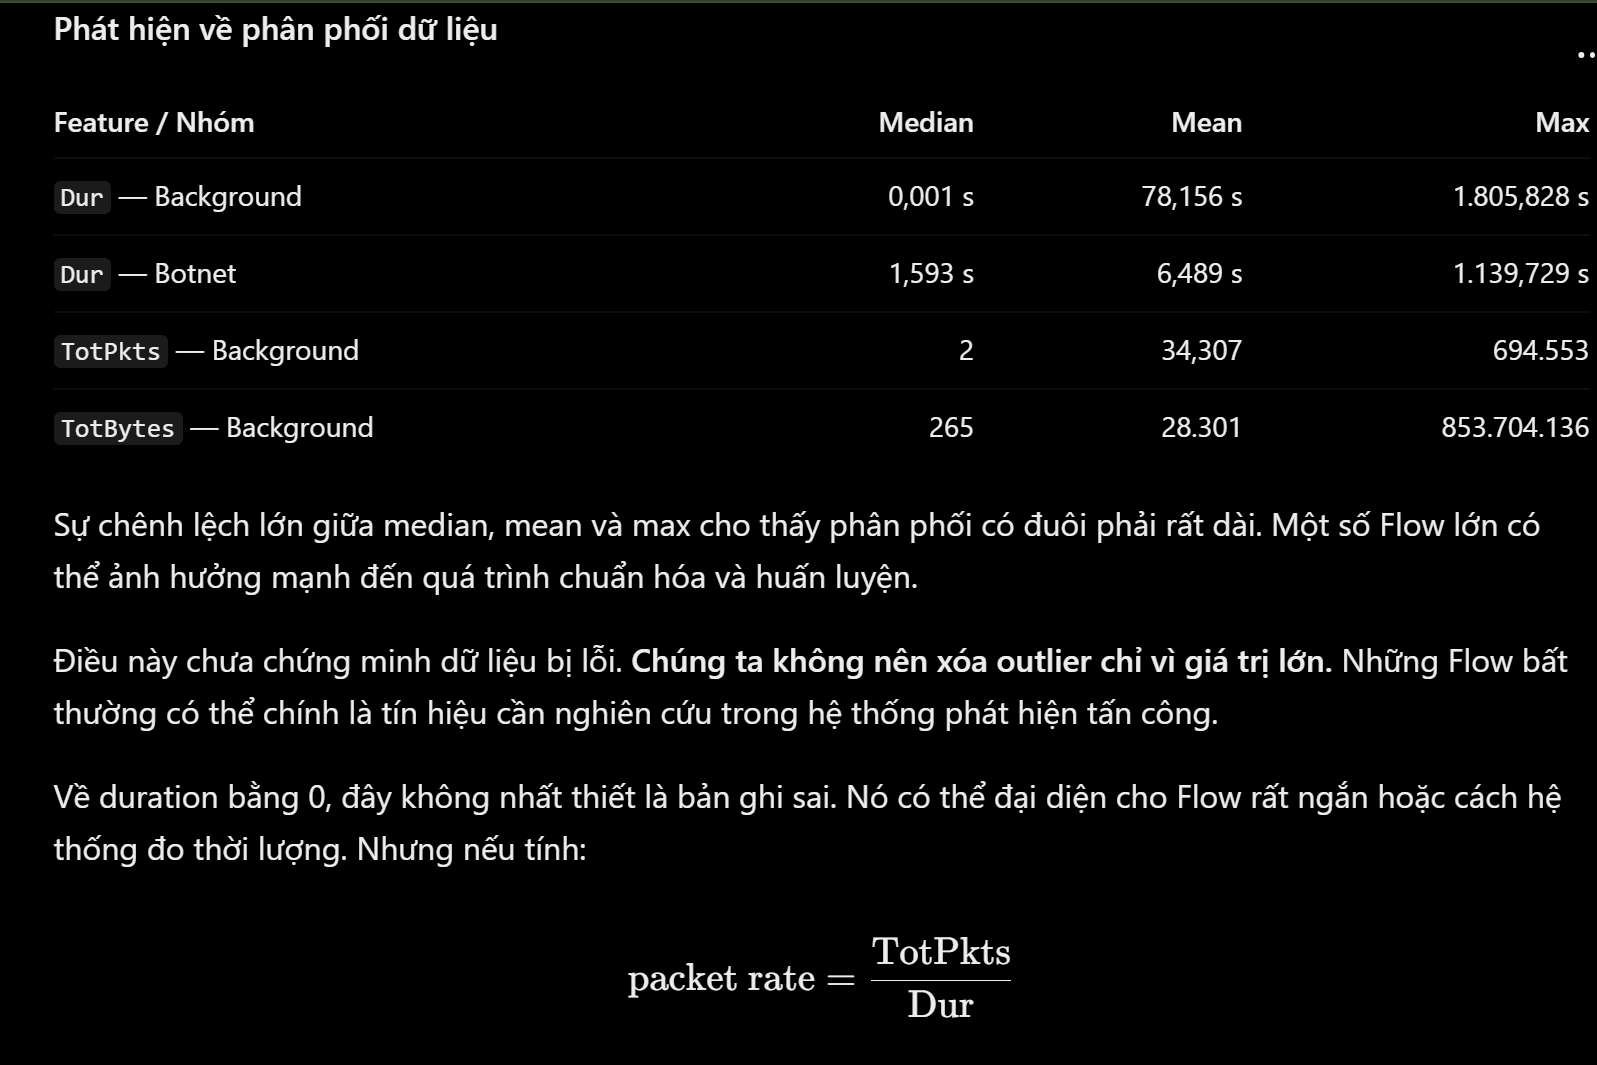

In [265]:

import numpy as np
import pandas as pd

# Preserve original CTU-13
mask = ctu_df["Proto"].str.lower().isin(["tcp", "udp"])

ctu_v1 = ctu_df.loc[
    mask,
    [
        "StartTime", "SrcAddr", "DstAddr",
        "Proto", "Dur", "TotPkts", "TotBytes"
    ]
].copy()

ctu_v1["LabelGroup"] = ctu_group.loc[ctu_v1.index]

ctu_v1 = ctu_v1.rename(columns={
    "Proto": "protocol",
    "Dur": "duration_s",
    "TotPkts": "total_packets",
    "TotBytes": "total_bytes"
})

ctu_v1["protocol"] = ctu_v1["protocol"].str.lower()

# Candidate model features
feature_columns = [
    "protocol",
    "duration_s",
    "total_packets",
    "total_bytes"
]

numeric_features = [
    "duration_s",
    "total_packets",
    "total_bytes"
]

print("=== FEATURE SCHEMA V1 ===")
print("Records:", len(ctu_v1))
print("Model features:", feature_columns)
display(ctu_v1[feature_columns].dtypes.to_frame("Dtype"))

print("\n=== LABEL DISTRIBUTION ===")
display(ctu_v1["LabelGroup"].value_counts())

# Validate values without modifying them
print("\n=== FEATURE VALIDATION ===")

X_numeric = ctu_v1[numeric_features].astype(float)

print("Missing:", int(X_numeric.isna().sum().sum()))
print("Non-finite:", int((~np.isfinite(X_numeric)).sum().sum()))
print("Negative:", int((X_numeric < 0).sum().sum()))

print("\n=== QUANTILE ANALYSIS BY LABEL ===")

for feature in numeric_features:
    print(f"\nFeature: {feature}")

    quantiles = (
        ctu_v1.groupby("LabelGroup")[feature]
        .quantile([0.50, 0.90, 0.99, 0.999])
        .unstack()
    )

    quantiles.columns = ["P50", "P90", "P99", "P99.9"]
    display(quantiles.round(3))

print("\n=== ZERO DURATION BY LABEL ===")

zero_duration = (
    ctu_v1.assign(
        IsZero=ctu_v1["duration_s"].eq(0)
    )
    .groupby("LabelGroup")["IsZero"]
    .agg(["sum", "count", "mean"])
)

zero_duration["mean"] *= 100
zero_duration.columns = [
    "ZeroCount", "Total", "ZeroPercent"
]

display(zero_duration.round(3))

print("\n=== STATUS ===")
print("Original dataset preserved.")
print("No rows removed from original.")
print("No imputation or scaling applied.")
print("No train/test split performed.")


=== FEATURE SCHEMA V1 ===
Records: 127439
Model features: ['protocol', 'duration_s', 'total_packets', 'total_bytes']


,Dtype
protocol,str
duration_s,float64
total_packets,int64
total_bytes,int64



=== LABEL DISTRIBUTION ===


LabelGroup
Background    121862
Normal          4676
Botnet           901
Name: count, dtype: int64


=== FEATURE VALIDATION ===
Missing: 0
Non-finite: 0
Negative: 0

=== QUANTILE ANALYSIS BY LABEL ===

Feature: duration_s


,P50,P90,P99,P99.9
LabelGroup,,,,
Background,0.001,88.042,1572.949,1786.375
Botnet,1.593,9.012,41.124,564.185
Normal,0.002,35.971,434.066,1738.481


... (3 outputs left out)

,P50,P90,P99,P99.9
LabelGroup,,,,
Background,265.0,4241.9,95769.97,1.840099e+06
Botnet,366.0,100495.0,555439.00,6.143831e+05
Normal,396.0,6444.0,188482.50,1.109071e+07



=== ZERO DURATION BY LABEL ===


,ZeroCount,Total,ZeroPercent
LabelGroup,,,
Background,1015,121862,0.833
Botnet,4,901,0.444
Normal,1,4676,0.021



=== STATUS ===
Original dataset preserved.
No rows removed from original.
No imputation or scaling applied.
No train/test split performed.
